# 04 - Risk scoring

`src/risk_score.py` scores every application with the saved model and keeps the latest
one per customer in the `scored_customers` table.

- risk_score = round(probability x 100)
- bands: 0-19 Low, 20-34 Medium, 35-100 High

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg2:///credit_risk")
scored = pd.read_sql("SELECT * FROM scored_customers", engine)
loans = pd.read_sql("SELECT application_id, loan_default FROM loan_applications", engine)
scored = scored.merge(loans, on="application_id")
print(scored.shape)
scored.head()

(3904, 11)


,customer_id,application_id,application_date,loan_type,approval_status,default_probability,risk_score,risk_category,predicted_default,top_factors,loan_default
0,CUST101468,APP800855,2022-07-01,Gold,Rejected,0.2250,22,Medium Risk,1,"num_defaults_prior, num_open_accounts, loan_te...",NaN
1,CUST103732,APP803898,2022-07-01,Auto,Rejected,0.4641,46,High Risk,1,"num_late_payments_30d, employment_type_Self-Em...",NaN
2,CUST100451,APP804590,2022-07-01,Home,Rejected,0.6564,66,High Risk,1,"debt_to_income_ratio, requested_amount, credit...",NaN
3,CUST101502,APP800947,2022-07-02,Home,Rejected,0.5688,57,High Risk,1,"debt_to_income_ratio, requested_amount, intere...",NaN
4,CUST104072,APP801474,2022-07-03,Home,Approved,0.6127,61,High Risk,1,"debt_to_income_ratio, requested_amount, loan_t...",1.0


## Why these bands

The PRD suggests 0-33 / 34-66 / 67-100, but the probabilities here are realistic (avg ~23%) so
almost nobody would end up High. Looking at the actual default rate for each score range on the
disbursed loans:

In [2]:
disbursed = scored[scored["loan_default"].notna()]
ranges = pd.cut(disbursed["risk_score"], [-1, 10, 15, 20, 25, 30, 35, 40, 50, 100])
disbursed.groupby(ranges, observed=True)["loan_default"].agg(["count", "mean"]).round(2)

,count,mean
risk_score,,
"(-1, 10]",281,0.06
"(10, 15]",348,0.09
"(15, 20]",281,0.19
"(20, 25]",236,0.26
"(25, 30]",169,0.22
"(30, 35]",120,0.36
"(35, 40]",95,0.41
"(40, 50]",118,0.53
"(50, 100]",108,0.45


In [3]:
disbursed.groupby("risk_category")["loan_default"].agg(["count", "mean"]).round(2)

,count,mean
risk_category,,
High Risk,345,0.47
Low Risk,862,0.10
Medium Risk,549,0.26


With 20 and 35 as the cut offs the default rate goes about 10% / 26% / 47%, so each band
means something clearly different. (These numbers include training loans so they're a bit
optimistic, the CV version in 03 gave 11% / 28% / 50%.)

## Distribution

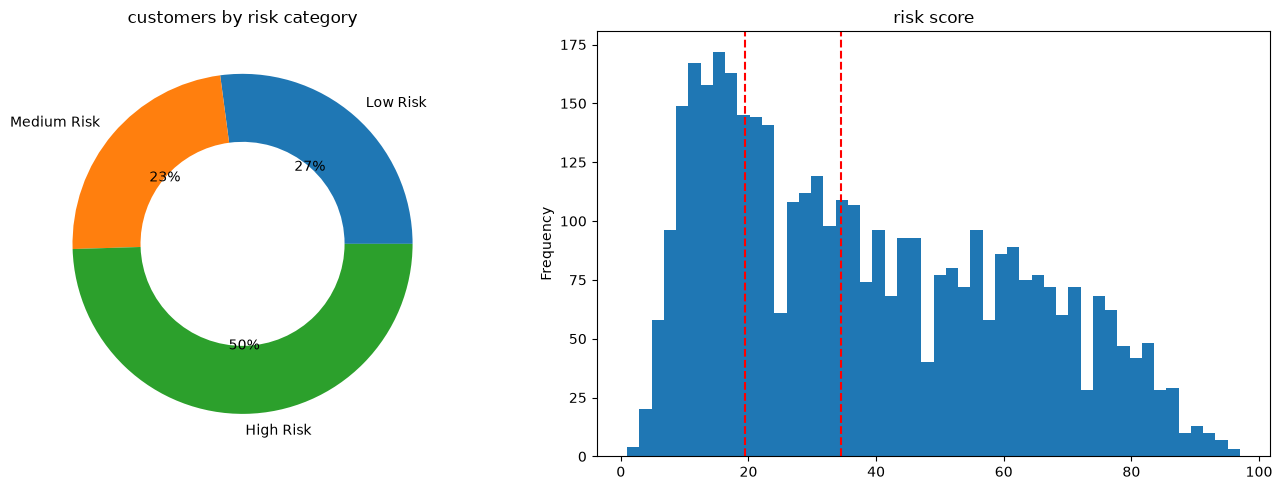

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scored["risk_category"].value_counts()[["Low Risk", "Medium Risk", "High Risk"]].plot.pie(
    ax=axes[0], autopct="%1.0f%%", wedgeprops={"width": 0.4}, ylabel="")
axes[0].set_title("customers by risk category")
scored["risk_score"].plot.hist(bins=50, ax=axes[1], title="risk score")
for x in [19.5, 34.5]:
    axes[1].axvline(x, color="red", ls="--")
plt.tight_layout()

In [5]:
pd.crosstab(scored["approval_status"], scored["risk_category"], normalize="index").round(2)

risk_category,High Risk,Low Risk,Medium Risk
approval_status,,,
Approved,0.20,0.49,0.31
Rejected,0.76,0.08,0.16
Under Review,0.50,0.24,0.26


Half the customers come out High Risk, but that's because a lot of customers' latest application
was rejected. The model agrees with the underwriters most of the time: ~76% of rejected
applications are High Risk vs ~20% of approved ones.

## Watchlist (approved loans only)

In [6]:
watchlist = (scored[(scored["approval_status"] == "Approved") & (scored["risk_category"] == "High Risk")]
             .sort_values("risk_score", ascending=False))
print(len(watchlist), "approved customers in the High Risk band")
watchlist[["customer_id", "loan_type", "risk_score", "top_factors"]].head(10)

345 approved customers in the High Risk band


,customer_id,loan_type,risk_score,top_factors
1680,CUST101112,Auto,93,"bankruptcies, debt_to_income_ratio, num_late_p..."
2613,CUST103192,Gold,82,"debt_to_income_ratio, num_late_payments_30d, c..."
3337,CUST101575,Home,79,"debt_to_income_ratio, credit_score, num_defaul..."
3679,CUST101631,Education,74,"num_late_payments_30d, credit_score, num_defau..."
1656,CUST104541,Education,74,"debt_to_income_ratio, num_late_payments_30d, l..."
3482,CUST104910,Personal,74,"debt_to_income_ratio, num_late_payments_30d, c..."
2314,CUST104300,Business,73,"debt_to_income_ratio, credit_score, credit_uti..."
2561,CUST102857,Business,73,"debt_to_income_ratio, num_defaults_prior, num_..."
728,CUST103419,Auto,72,"num_late_payments_30d, credit_score, num_defau..."
3365,CUST104303,Education,72,"num_late_payments_30d, debt_to_income_ratio, c..."


In [7]:
watchlist["top_factors"].str.split(", ").explode().value_counts().head(8)

top_factors
debt_to_income_ratio             174
credit_score                     167
num_late_payments_30d            136
loan_term_months                  92
requested_amount                  81
interest_rate                     77
employment_type_Self-Employed     65
num_open_accounts                 42
Name: count, dtype: int64

## Notes

- 3,904 customers scored. The other 1,096 customers never applied for a loan, and the model needs
  application details (amount, DTI, loan type), so they can't get a score.
- Rejected and under-review applications are scored with a model that only learned from
  disbursed loans, so their scores are less reliable.
- `top_factors` gives the 3 features pushing each score up the most (SHAP), so every score can be explained.